<a href="https://colab.research.google.com/github/Angela-Benedict/ds2002-fa26/blob/main/notebooks/walmart-hurricane-project/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
#cleaned data:
import pandas as pd

!git clone https://github.com/Angela-Benedict/ds2002-fa26.git

sales = pd.read_csv(
    "ds2002-fa26/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)
q1 = sales.drop_duplicates().copy()

q1["timestamp"] = pd.to_datetime(q1["timestamp"], format="mixed", errors="coerce")
q1["date"] = q1["timestamp"].dt.normalize()
q1["quantity"] = pd.to_numeric(q1["quantity"], errors= "coerce")

q1['category_clean'] = (
    q1["category"]
    .astype(str)
    .str.strip()
    .str.lower()
)

category_map = {
    "emergency": "Emergency Supplies",
    'emergency supplies': "Emergency Supplies",
    "groceries": "Groceries",
    "grocery": "Groceries",
    "electronics": "Electronics",
    "household": "Household",
    "household essentials": "Household",
    "baby": "Baby Products",
    "baby products": "Baby Products",
    "breakfast": "Breakfast Foods",
    "breakfast foods":"Breakfast Foods",
    "health":"Health",
    "health & wellness":"Health",
    "alcohol":"Alcohol",
    "alcoholic beverages":"Alcohol",
    'games & entertainment':"Entertainment",
    "entertainment":"Entertainment",
    "snacks":"Snacks"
}
q1["category_clean"] = q1["category_clean"].map(category_map)

daily_category = (
    q1.groupby(["date", "category_clean"]) ["quantity"]
    .sum()
    .reset_index()
)

Cloning into 'ds2002-fa26'...
remote: Enumerating objects: 401, done.
remote: Counting objects: 100% (160/160), done.
remote: Compressing objects: 100% (160/160), done.
remote: Total 401 (delta 91), reused 0 (delta 0), pack-reused 241 (from 1)
Receiving objects: 100% (401/401), 2.36 MiB | 9.51 MiB/s, done.
Resolving deltas: 100% (169/169), done.


In [2]:
#The numbers:
landfall = pd.Timestamp("2024-9-26")

baseline = daily_category[
    (daily_category["date"] >= "2024-9-08") &
    (daily_category["date"] <= "2024-9-15")
]
surge = daily_category[
    (daily_category["date"] >= "2024-9-19") &
    (daily_category["date"] <= "2024-9-25")
]

baseline_avg = baseline.groupby("category_clean")["quantity"].mean()
surge_avg = surge.groupby("category_clean")["quantity"].mean()
surge_multiple = surge_avg / baseline_avg

percent_increase = (surge_multiple - 1) * 100

q1_results = pd.DataFrame({
    "baseline_avg": baseline_avg,
    "pre_landfall_avg": surge_avg,
    "surge_multiple": surge_multiple,
    "percent_increase": percent_increase
}).sort_values("percent_increase", ascending=False)

daily_wide=daily_category.pivot(
    index='date',
    columns='category_clean',
    values = 'quantity'
)

q1_results.round(2)

,baseline_avg,pre_landfall_avg,surge_multiple,percent_increase
category_clean,,,,
Breakfast Foods,72.75,375.71,5.16,416.45
Emergency Supplies,350.62,1002.29,2.86,185.86
Electronics,69.62,175.29,2.52,151.76
Alcohol,59.25,138.29,2.33,133.39
Health,40.62,94.14,2.32,131.74
Entertainment,101.88,227.00,2.23,122.82
Household,83.75,175.86,2.10,109.98
Groceries,169.25,305.29,1.80,80.38
Baby Products,85.50,132.57,1.55,55.05


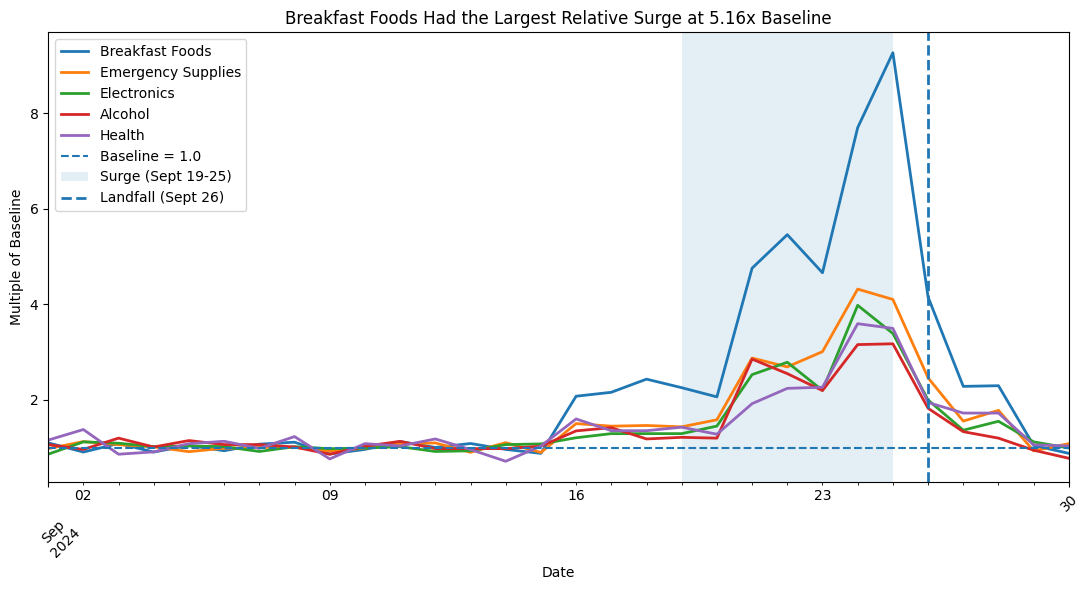

                    surge_multiple  percent_increase
category_clean                                      
Breakfast Foods               5.16            416.45
Emergency Supplies            2.86            185.86
Electronics                   2.52            151.76
Alcohol                       2.33            133.39
Health                        2.32            131.74


In [3]:
#The table:
import matplotlib.pyplot as plt

top5 = q1_results.head(5).index.tolist()

indexed_q1 = daily_wide[top5].div(baseline_avg[top5])

ax = indexed_q1.plot(figsize=(11, 6), linewidth=2)

ax.axhline(1.0, linestyle="--", linewidth=1.5, label="Baseline = 1.0")

ax.axvspan(
    surge["date"].min(),
    surge["date"].max(),
    alpha=0.12,
    label="Surge (Sept 19-25)"
)

ax.axvline(
    pd.Timestamp("2024-09-26"),
    linestyle="--",
    linewidth=2,
    label="Landfall (Sept 26)"
)

ax.set_title("Breakfast Foods Had the Largest Relative Surge at 5.16x Baseline")
ax.set_xlabel("Date")
ax.set_ylabel("Multiple of Baseline")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

baseline_avg = baseline.mean(numeric_only=True)
surge_avg = surge.mean(numeric_only=True)
surge_multiple = surge_avg / baseline_avg

percent_increase = (surge_multiple - 1) * 100

print(q1_results[["surge_multiple", "percent_increase"]].head(5).round(2))

**Q1 answer, in one sentence a manager could read:** Comparing the 7 days prior to landfall (September 19-25) to a flat baseline week (September 8-15), Breakfast Foods saw the biggest spike, selling 5.16 times their regular sales per day (416% increase), followed by Emergency Supplies at 2.86x (186% increase).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [4]:
import pandas as pd

url = "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/main/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
sales = pd.read_csv(url).drop_duplicates()
sales["quantity"] = pd.to_numeric(sales["quantity"], errors="coerce")
sales["name_clean"] = sales["product_name"].str.strip().str.lower()

print("Distinct SKUs before:", sales["sku"].nunique())
print("Distinct product names before:", sales["product_name"].nunique())

# skus sold under the same name are the same product
parent = {sku: sku for sku in sales["sku"].unique()}

def find(sku):
    while parent[sku] != sku:
        sku = parent[sku]
    return sku

for name, skus in sales.groupby("name_clean")["sku"].unique().items():
    for sku in skus[1:]:
        parent[find(sku)] = find(skus[0])

sales["group"] = sales["sku"].map(find)
canonical = sales.groupby("group")["product_name"].agg(lambda x: x.str.strip().value_counts().index[0])
sales["product_canonical"] = sales["group"].map(canonical)

print("Canonical products after:", sales["product_canonical"].nunique())

families = sales.groupby("product_canonical")["sku"].unique()
largest = families.str.len().idxmax()
print("Largest family:", largest)
print("SKUs in largest family:", list(families[largest]))

units_before = sales.groupby("sku")["quantity"].sum().sum()
units_after = sales.groupby("product_canonical")["quantity"].sum().sum()
assert units_before == units_after
print("Unit totals before and after:", units_before, units_after)

sales.groupby("product_canonical")["sku"].nunique().sort_values(ascending=False)

Distinct SKUs before: 45
Distinct product names before: 63
Canonical products after: 20
Largest family: Pop-Tarts Strawberry
SKUs in largest family: ['PT_STRAWBERRY', 'SKU#459812', 'PT-12', 'POPTART-STRAW']
Unit totals before and after: 49343 49343


,sku
product_canonical,
Pop-Tarts Strawberry,4
AA Batteries 4-Pack,3
Bottled Water 24-Pack,3
Board Game - Monopoly,3
BABY FORMULA,2
CANDLES - EMERGENCY,2
First-Aid Kit,2
Diapers Size 3,2
LED Flashlight,2


In [5]:
# Find all Pop-Tart sales
poptarts = sales[
    sales['product_canonical'].str.contains('pop.?tart', case=False, na=False)
].copy()

# Convert timestamp into a date
poptarts['date'] = pd.to_datetime(
    poptarts['timestamp'],
    format='mixed',
    dayfirst=True
).dt.date

# Calculate total Pop-Tart units sold each day
daily_sales = (
    poptarts.groupby('date')['quantity']
    .sum()
    .reset_index(name='total_poptarts_sold')
)

print("Daily Pop-Tart Sales Volume:")
display(daily_sales)

# Calculate average daily sales volume
print("Average Pop-Tarts sold daily:", daily_sales['total_poptarts_sold'].sum()/daily_sales['date'].nunique())

Daily Pop-Tart Sales Volume:


,date,total_poptarts_sold
0,2024-01-09,26
1,2024-02-09,20
2,2024-03-09,20
3,2024-04-09,22
4,2024-05-09,20
5,2024-06-09,15
6,2024-07-09,28
7,2024-08-09,32
8,2024-09-01,54
9,2024-09-02,46


Average Pop-Tarts sold daily: 121.58536585365853


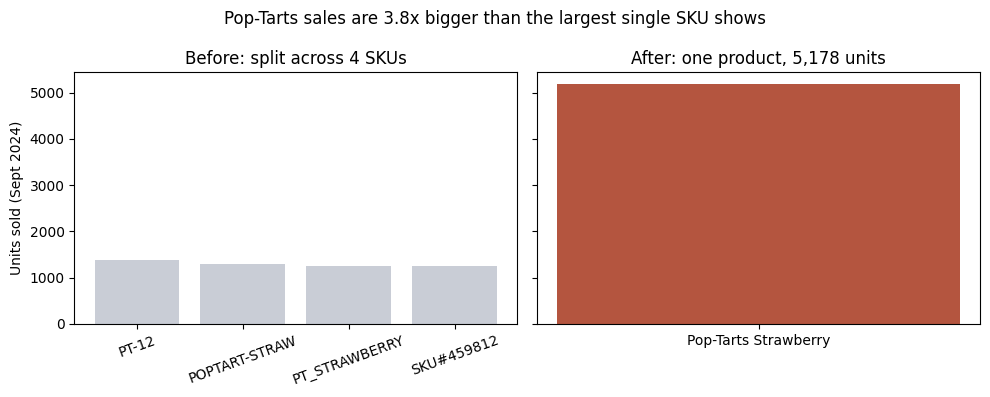

Largest single SKU: 1377 | Consolidated: 5178


In [6]:
import matplotlib.pyplot as plt

pop = sales[sales["product_canonical"] == largest]
before = pop.groupby("sku")["quantity"].sum().sort_values(ascending=False)
after = before.sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].bar(before.index, before.values, color="#c9cdd6")
axes[0].set_title("Before: split across 4 SKUs")
axes[0].set_ylabel("Units sold (Sept 2024)")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar([largest], [after], color="#b4553f")
axes[1].set_title(f"After: one product, {after:,.0f} units")
fig.suptitle(f"Pop-Tarts sales are {after / before.max():.1f}x bigger than the largest single SKU shows")
plt.tight_layout()
plt.show()

print("Largest single SKU:", before.max(), "| Consolidated:", after)

**Q2 answer:** We started out with 45 SKUs and 63 product names, but ended up consolidating to 20 products without any change in units (49,343 before consolidation and after consolidation). Looking at average daily poptart sales volume, we can see about 121 are sold a day. The biggest product family is Pop-Tarts Strawberry (4 SKUs), where the biggest SKU has only 1,377 units. Nevertheless, the consolidated product had 5,178 units, so the fragmented view understates demand by 3.8 times. Business decisions could differ if you take into account package size which we ignored here by consolidating. Maybe customers only will buy a certain size box.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [7]:
import pandas as pd, requests, matplotlib.pyplot as plt

# 1. sales: load, remove duplicates, parse the mixed timestamp formats, count orders per day
DATA_URL = ("https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/refs/heads/main/"
            "notebooks/walmart-hurricane-project/data/walmart_transactions.csv")
sales = pd.read_csv(DATA_URL).drop_duplicates()
sales["date"] = pd.to_datetime(sales["timestamp"], format="mixed", errors="coerce").dt.normalize()
daily_sales = sales.dropna(subset=["date"]).groupby("date").size().reset_index(name="orders")

# 2. weather: Open-Meteo Historical API, Orlando, daily buckets in Eastern time to match the sales data
BASE = "https://archive-api.open-meteo.com/v1/archive"
params = {"latitude": 28.54, "longitude": -81.38,
          "start_date": "2024-09-01", "end_date": "2024-09-30",
          "daily": "precipitation_sum,windspeed_10m_max",
          "timezone": "America/New_York"}
r = requests.get(BASE, params=params, timeout=10)
r.raise_for_status()
weather = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})
weather["date"] = pd.to_datetime(weather["date"])
weather["source"] = "open-meteo (live)"

# 3. validated left join: no sales day lost, no orders lost
sales_weather = daily_sales.merge(weather, on="date", how="left")
assert len(sales_weather) == len(daily_sales), "join changed the row count"
assert sales_weather["orders"].sum() == daily_sales["orders"].sum(), "join changed total orders"

print("weather source:     ", weather["source"].iloc[0])
print("sales days before:  ", len(daily_sales))
print("rows after join:    ", len(sales_weather))
print("days missing weather:", sales_weather["windspeed_10m_max"].isna().sum())

# 4. same-day correlation and lag (orders vs wind k days later)
n_days = len(sales_weather)
print(f"\nsame-day r, wind: {sales_weather['orders'].corr(sales_weather['windspeed_10m_max']):.3f}  (n = {n_days})")
print(f"same-day r, rain: {sales_weather['orders'].corr(sales_weather['precipitation_sum']):.3f}  (n = {n_days})")

lags = []
for k in range(0, 8):
    wind_later = sales_weather["windspeed_10m_max"].shift(-k)
    lags.append({"days_orders_lead_wind": k,
                 "r": round(sales_weather["orders"].corr(wind_later), 3),
                 "n_pairs": int(wind_later.notna().sum())})
lags = pd.DataFrame(lags)
print(lags.to_string(index=False))

weather source:      open-meteo (live)
sales days before:   30
rows after join:     30
days missing weather: 0

same-day r, wind: 0.391  (n = 30)
same-day r, rain: -0.250  (n = 30)
 days_orders_lead_wind     r  n_pairs
                     0 0.391       30
                     1 0.709       29
                     2 0.823       28
                     3 0.676       27
                     4 0.454       26
                     5 0.293       25
                     6 0.135       24
                     7 0.057       23


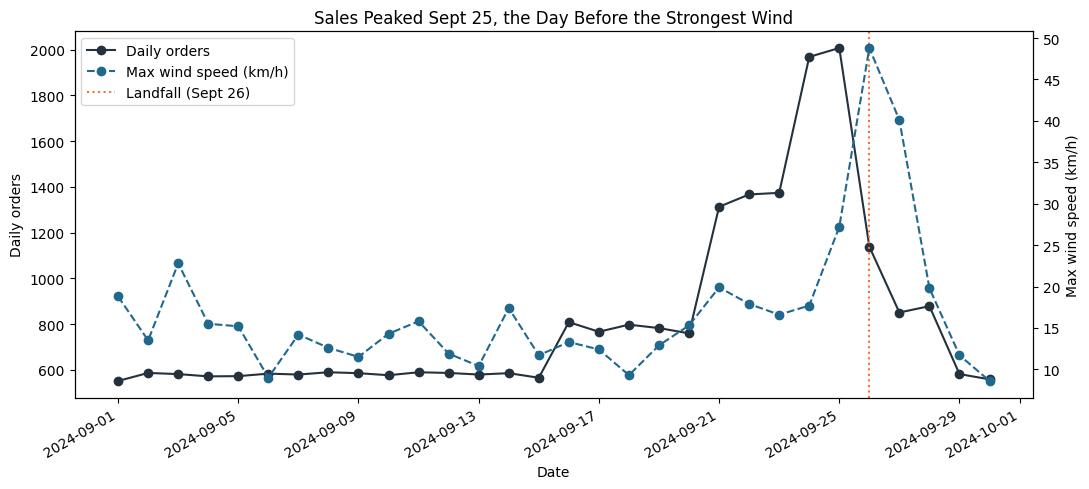

In [8]:
fig, ax1 = plt.subplots(figsize=(11, 5))
l1 = ax1.plot(sales_weather["date"], sales_weather["orders"], marker="o", color="#24323E", label="Daily orders")
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily orders")
ax2 = ax1.twinx()
l2 = ax2.plot(sales_weather["date"], sales_weather["windspeed_10m_max"], marker="o", linestyle="--",
              color="#21688D", label="Max wind speed (km/h)")
ax2.set_ylabel("Max wind speed (km/h)")
l3 = [ax1.axvline(pd.Timestamp("2024-09-26"), color="#F67132", linestyle=":", label="Landfall (Sept 26)")]
lines = l1 + l2 + l3
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")
plt.title("Sales Peaked Sept 25, the Day Before the Strongest Wind")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** With real-time Open-Meteo data (Orlando, Eastern time), all 30 sales days matched without losing any data rows (30 pre-match, 30 post-match). On the same day, wind is correlated with daily sales orders at r = 0.391 (n = 30 days). This correlation is strongest when orders are correlated with wind two days ahead (r = 0.823, n = 28 days): sales peaked on September 25, the day prior to the greatest wind speed on September 26 (landfall). Caveat: this is just one month’s worth of data from one location’s weather, so this is a timing correlation, not causation.


### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** We were having some trouble joining the data, but Nico will finish it before presentations.

**Q5 (signal or artifact):** Since this question is a culmination of everything, we have put it off a bit, but Angela has begun working on it to finish before presentations.

### Self-check

In [9]:
progress = {
    'q1_multiple': 5.16,
    'q1_baseline_window': 'Sept 8-15 (surge Sept 19-25)',
    'q2_canonical_products': 20,
    'q3_join_rows_preserved': True,
    'q3_days_in_correlation': 30,
    'charts_with_message_titles': 3,
    'notebook_runs_clean': True,
    'repo_pushed': True,
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.16
PASS - q1_baseline_window = Sept 8-15 (surge Sept 19-25)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)**  Breakfast Foods showed higher sales growth than Emergency Supplies (5.16x vs 2.86x baseline in the 7 days prior to landfall), despite the fact that Emergency Supplies had greater unit sales. The initial results provided smaller figures, but we identified that it was due to a parsing error: there are 5 formats for timestamps, and without format="mixed", only 2,511 out of 25,562 rows had a date. Breakfast Foods ranked #1 in both cases: initially (4.43x) and then with the correct data (5.16x), so the result wasn’t caused by the bug. This is consistent with the Pop-Tarts case.

**b)** The 2 day lag correlation between orders and wind (r = 0.823; n = 28 pairs). This is using data from one month and one weather location (Orlando) which represents all the stores, and the API values are slightly different each time: a previous calculation gave r = 0.834. The timing is the same (sales peak on September 25; wind peak on September 26), but the r value is slightly variable.
